# Distance from one image: metric-depth comparison

Compare models on the same RGB images and depth labels in meters. Pixel depth is separate from object detection: it can be tested without boxes. Assigning distance to a particular object is a later fusion step.

## 1. Choose settings

The metric models predict meters directly. MiDaS predicts relative inverse depth and is a separate diagnostic; fitting it to evaluation labels cannot show deployable distance accuracy.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'notebooks/_support').is_dir())
sys.path.insert(0, str(ROOT / 'notebooks/_support'))
from common import save_run, comparison_plot

MAX_SAMPLES = 100  # Small first run. Set None for the full validation set.
SEED = 42         # Every model gets the exact same seeded sample list.
EXAMPLES = 3      # Same randomly selected examples for every model.
import torch
import depth
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
MANIFEST = ROOT / 'data/depth/manifest.csv'
MODELS = depth.MODELS
display(pd.DataFrame(MODELS)[['name', 'mode', 'description']])


,name,mode,description
0,Depth Anything V2 Small,metric,Small outdoor metric model; predicts camera-ax...
1,Depth Anything V2 Base,metric,Larger outdoor metric model; compare accuracy ...
2,MiDaS DPT-Hybrid,relative,Relative inverse-depth model; oracle-aligned d...


## 2. Load paired images and depth labels

The CSV contains `image,depth,depth_scale,split`. Paths are relative to the CSV; only `split=val` is used. Depth arrays must align with image pixels and represent camera-axis depth, not radial range. Divide stored values by `depth_scale` to get meters; zero is invalid.

nuScenes needs calibrated, time-compensated LiDAR projection first. Occ3D voxel labels and BDD boxes are not per-pixel metric-depth labels. No depth manifest has been prepared in this project yet.

In [2]:
samples = depth.load_samples(MANIFEST, MAX_SAMPLES, SEED)
print('Paired validation samples:', len(samples))

Paired validation samples: 100


## 3. Run every model on those same samples

Timing uses batch size 1, FP32, three warm-up predictions, and CUDA synchronization.
It includes preprocessing, model execution and postprocessing; image loading, downloads and model loading are excluded.
Mean/p95 are milliseconds per image. Reciprocal mean latency is serial throughput, not phone or streaming-app FPS.
Model-native resizing is retained (SSD uses 300 pixels; the other detector adapters use a 640-pixel limit).

Depth metrics use valid labels in (0, 80] meters. Errors are calculated per image and then averaged equally across images. Non-finite predictions fail the run rather than silently removing difficult pixels.

In [3]:
rows, visuals = [], {}
for model in MODELS:
    print(f"Evaluating {model['name']}...")
    row, examples = depth.evaluate_model(ROOT, model, samples, DEVICE, EXAMPLES)
    rows.append(row)
    visuals[model['name']] = examples
    display(pd.DataFrame([row]))
results = save_run(ROOT, 'depth', samples, {'seed':SEED, 'device':DEVICE, 'max_depth_m':80}, rows)


Evaluating Depth Anything V2 Small...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


,model,description,mode,frames,device,status,abs_rel,rmse_m,delta1,valid_pixels,mean_ms,p95_ms,images_per_second
0,Depth Anything V2 Small,Small outdoor metric model; predicts camera-ax...,metric,100,cpu,ok,0.387322,8.104547,0.22968,282957,1350.808361,1483.287005,0.740297


Evaluating Depth Anything V2 Base...


,model,description,mode,frames,device,status,abs_rel,rmse_m,delta1,valid_pixels,mean_ms,p95_ms,images_per_second
0,Depth Anything V2 Base,Larger outdoor metric model; compare accuracy ...,metric,100,cpu,ok,0.385954,7.412218,0.227679,282957,3323.866331,3720.84061,0.300854


Evaluating MiDaS DPT-Hybrid...


,model,description,mode,frames,device,status,abs_rel,rmse_m,delta1,valid_pixels,mean_ms,p95_ms,images_per_second
0,MiDaS DPT-Hybrid,Relative inverse-depth model; oracle-aligned d...,relative,100,cpu,ok,0.153686,7.976487,0.802567,282957,1170.726571,1413.84734,0.85417


## 4. Read the metric comparison

Lower **AbsRel** (relative error) and **RMSE** (meters) are better. Higher **delta1** is better: fraction of labeled pixels within a factor of 1.25. MiDaS is shown separately because it uses oracle scale/shift fitting against ground truth.

,model,description,mode,frames,device,status,abs_rel,rmse_m,delta1,valid_pixels,mean_ms,p95_ms,images_per_second
0,Depth Anything V2 Small,Small outdoor metric model; predicts camera-ax...,metric,100,cpu,ok,0.387322,8.104547,0.229680,282957,1350.808361,1483.287005,0.740297
1,Depth Anything V2 Base,Larger outdoor metric model; compare accuracy ...,metric,100,cpu,ok,0.385954,7.412218,0.227679,282957,3323.866331,3720.840610,0.300854


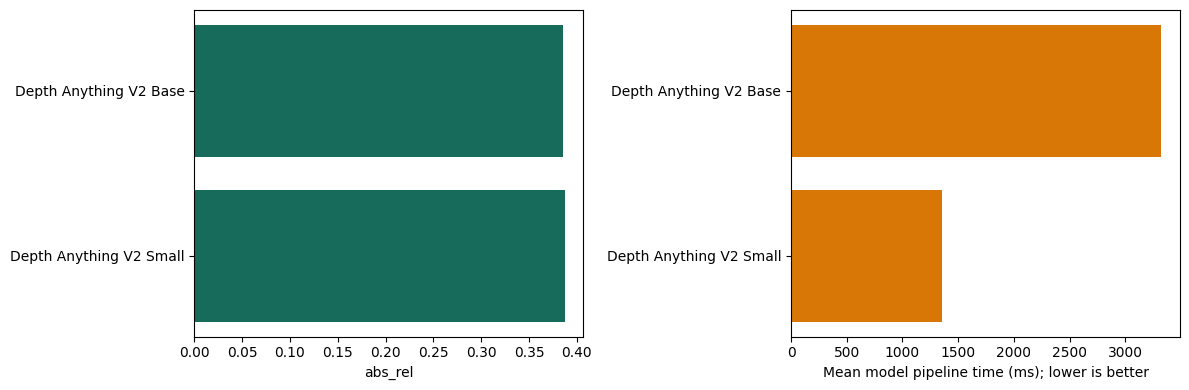

,model,description,mode,frames,device,status,abs_rel,rmse_m,delta1,valid_pixels,mean_ms,p95_ms,images_per_second
2,MiDaS DPT-Hybrid,Relative inverse-depth model; oracle-aligned d...,relative,100,cpu,ok,0.153686,7.976487,0.802567,282957,1170.726571,1413.84734,0.85417


In [4]:
display(results[results['mode'] == 'metric'])
comparison_plot(results[results['mode'] == 'metric'], 'abs_rel')
display(results[results['mode'] == 'relative'])

## 5. Visually compare with actual depth

Ground truth and predictions share the same 0–80 m color scale. Error is shown only where labels exist; an unlabeled pixel is not zero error.

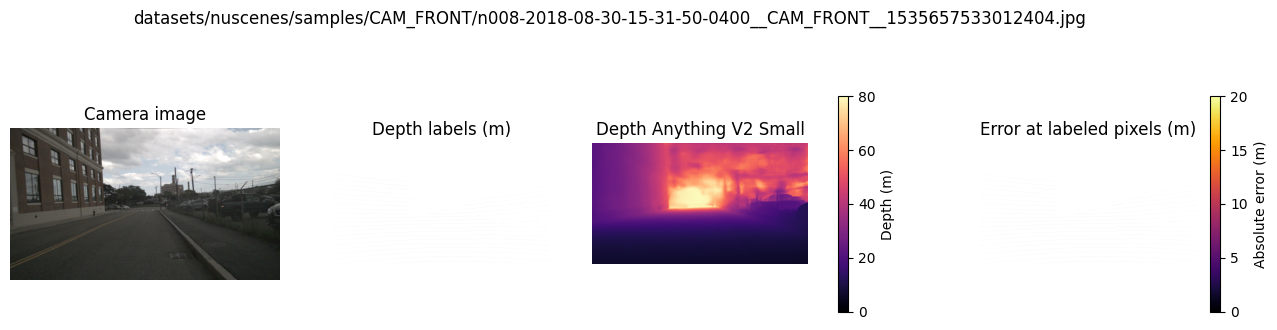

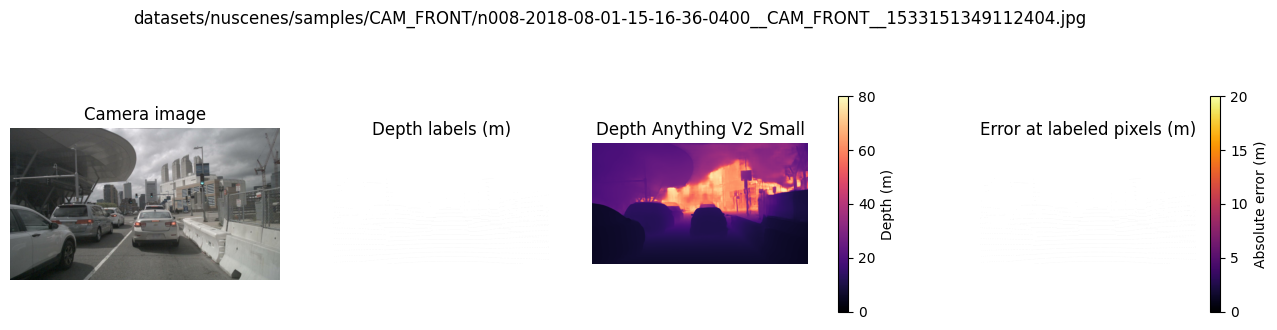

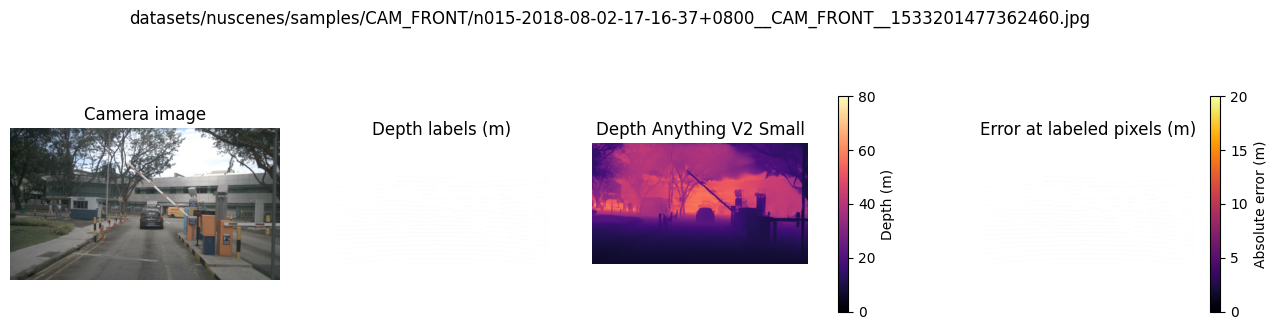

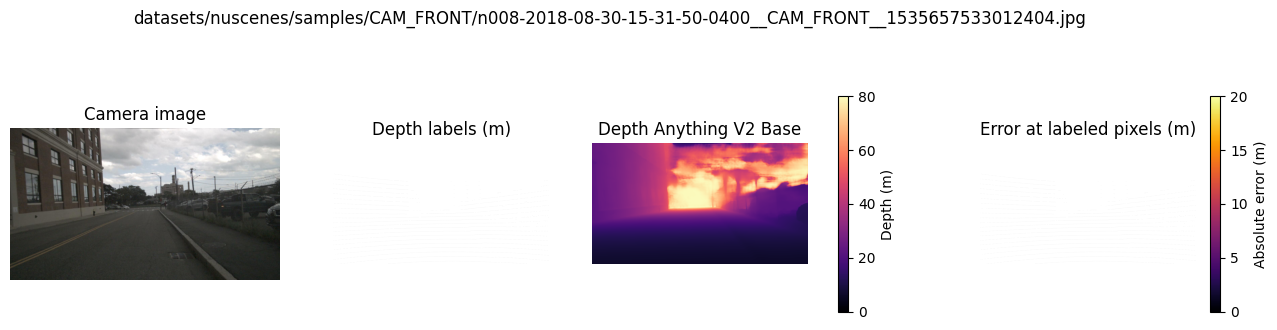

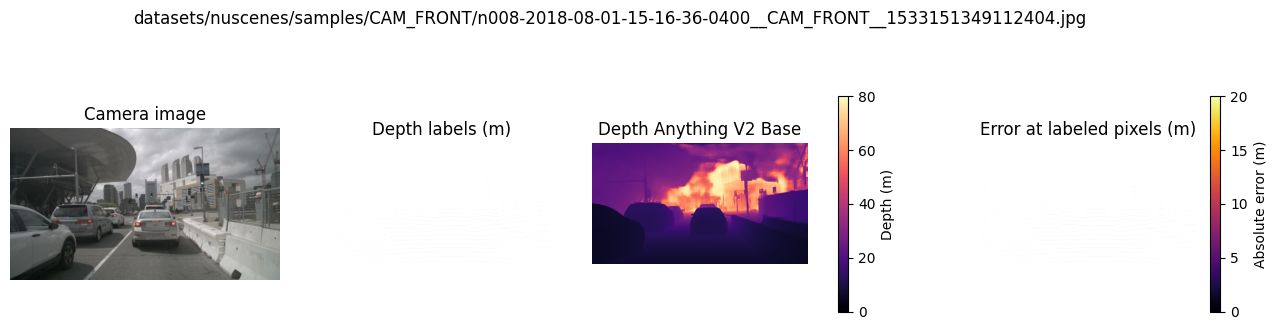

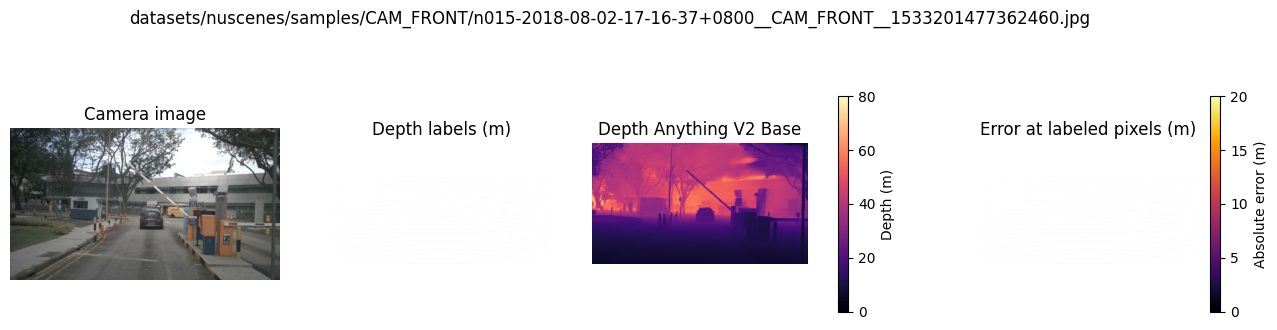

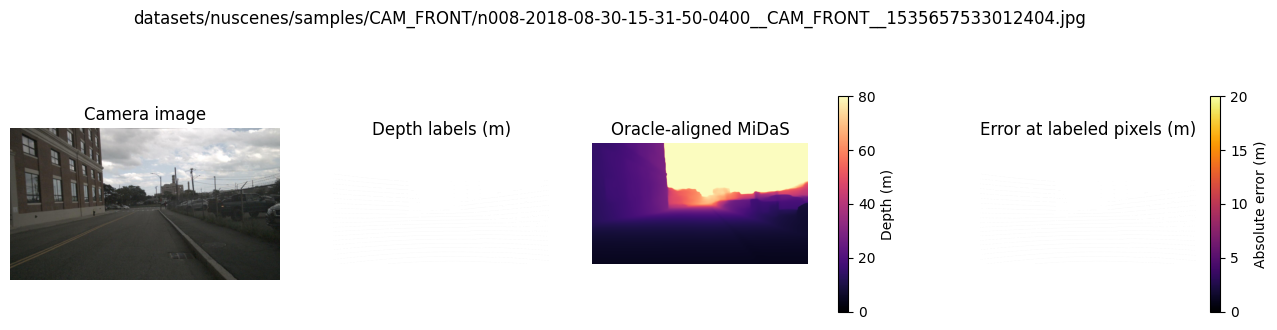

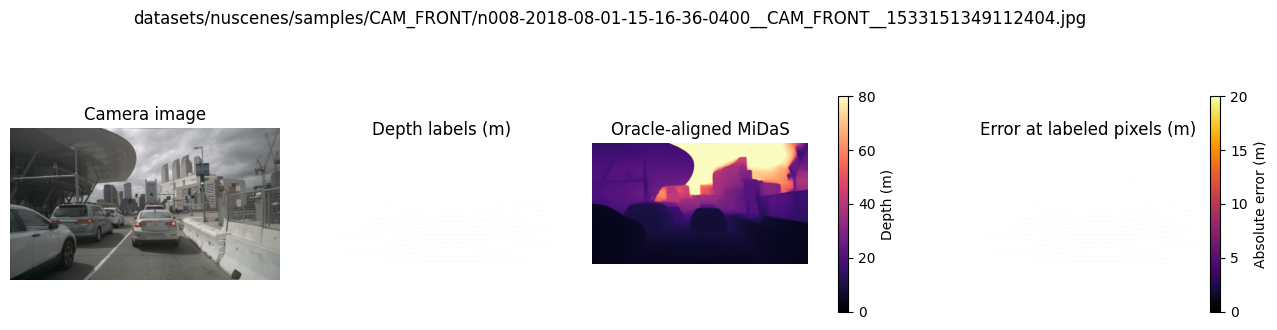

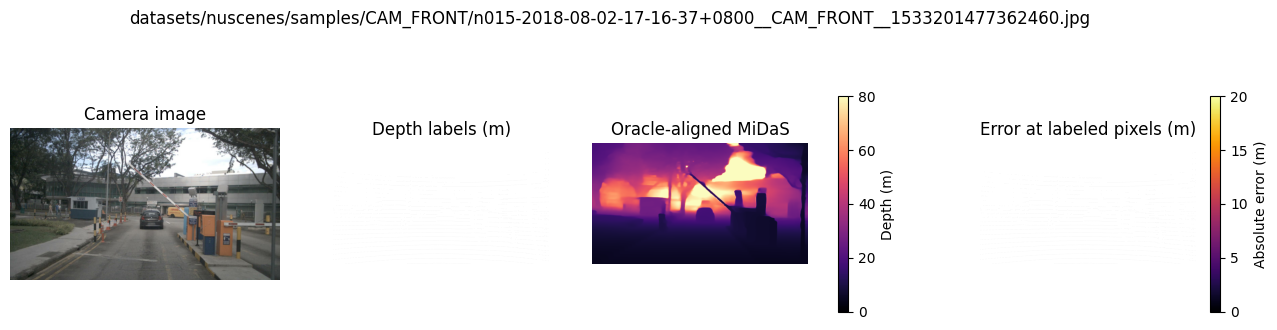

In [5]:
for model in MODELS:
    depth.show_examples(model, visuals[model['name']])

## What this tells us

This compares surface depth under the supplied label convention. Object-center distance and distance to the nearest surface are different targets. Tracking, temporal consistency and collision-warning timing require separate tests.